# Import libraries

In [1]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

# Load clean data

In [2]:
df = pd.read_csv("/Users/anhtuyet15999/Projects/education/data/processed/clean_education.csv")

In [3]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter,locale,locale_group
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes,21.0,Suburban
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No,31.0,Town
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No,41.0,Rural
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No,32.0,Town
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No,22.0,Suburban


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7227 entries, 0 to 7226
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7227 non-null   int64  
 1   rate_unemployment  7227 non-null   float64
 2   percent_college    7227 non-null   float64
 3   percent_married    7227 non-null   float64
 4   median_income      7227 non-null   float64
 5   average_act        7227 non-null   float64
 6   percent_lunch      7227 non-null   float64
 7   year               7227 non-null   str    
 8   state              7227 non-null   str    
 9   zip_code           7227 non-null   int64  
 10  school_type        7227 non-null   str    
 11  school_level       7227 non-null   str    
 12  charter            7227 non-null   str    
 13  locale             7227 non-null   float64
 14  locale_group       7227 non-null   str    
dtypes: float64(7), int64(2), str(6)
memory usage: 1.1 MB


# Exploratory Data Analysis

## Sample Overview

This section describes the schools included in the analytical sample, including their geographic coverage and locale distribution.

### Numbers of schools and states

In [5]:
df['id'].nunique()

7227

In [6]:
df['state'].nunique()

20

There are 7227 schools and 20 states.

### Numbers of schools by locale_group

In [7]:
df["locale_group"].value_counts()

locale_group
Rural       2256
Suburban    2235
City        1628
Town        1108
Name: count, dtype: int64

In [8]:
df["locale_group"].value_counts()/len(df) * 100

locale_group
Rural       31.216272
Suburban    30.925695
City        22.526636
Town        15.331396
Name: count, dtype: float64

Schools in rural areas account for the largest proportion (31.22%), followed by those in suburban areas (30.92%), cities (22.53%), and towns (15.33%).

### Numbers of schools by state

In [9]:
df["state"].value_counts()

state
TX    913
OH    654
IL    564
PA    543
MI    498
NC    407
FL    404
GA    367
WI    351
NJ    338
MO    337
IN    321
NY    295
TN    265
WA    263
MA    253
KY    198
LA    194
WY     38
DE     24
Name: count, dtype: int64

In [10]:
df["state"].value_counts()/len(df) * 100

state
TX    12.633181
OH     9.049398
IL     7.804068
PA     7.513491
MI     6.890826
NC     5.631659
FL     5.590148
GA     5.078179
WI     4.856787
NJ     4.676906
MO     4.663069
IN     4.441677
NY     4.081915
TN     3.666805
WA     3.639131
MA     3.500761
KY     2.739726
LA     2.684378
WY     0.525806
DE     0.332088
Name: count, dtype: float64

### Summary
The dataset includes schools from 20 states. Texas accounts for the largest proportion (12.63%), while the five most represented states (Texas, Ohio, Illinois, Pennsylvania, and Michigan) together account for 43.89% of schools. Wyoming and Delaware contribute the smallest precentages, at 0.53% and 0.33%, respectively. Therefore, results may be affected more strongly by states with larger numbers of schools in the dataset.

## Distribution of Average ACT Scores

### Summary Statistics

In [11]:
df["average_act"].describe().to_frame()

,average_act
count,7227.000000
mean,20.298577
std,2.508415
min,12.362637
25%,18.800000
50%,20.500000
75%,22.000000
max,32.362637


Across 7,227 schools, the mean average ACT score is 20.30, with a median of 20.50 and a standard deviation of 2.51. The middle 50% of schools have average scores between 18.80 and 22.00, giving an interquartile range of 3.20 points. School average scores range from 12.36 to 32.36.

### Plot histogram of the distribution of Average ACT Scores

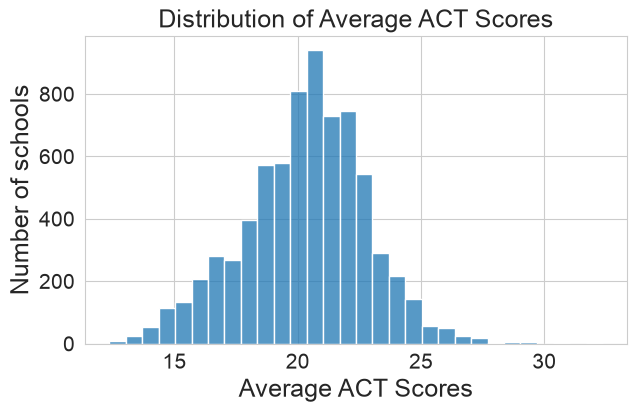

In [12]:
plt.figure(figsize=(7,4))

sns.histplot(data = df, x='average_act', bins=30)

plt.xlabel('Average ACT Scores', fontsize=18)
plt.ylabel('Number of schools', fontsize=18)
plt.title('Distribution of Average ACT Scores', fontsize=18)

plt.tick_params(labelsize=15)

plt.show()

The distribution of school average ACT scores is approximately bell-shaped, with a peak around 20–21. Scores are concentrated roughly between 18 and 23, while relatively few schools have average scores below 15 or above 25.

### Plot boxplot to identify spread and potential outliers

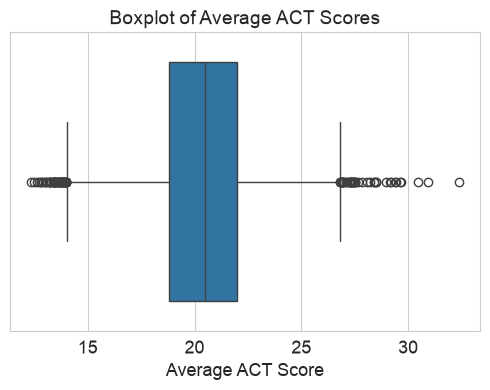

In [13]:
plt.figure(figsize=(5,4))

sns.boxplot(data = df, x='average_act')

plt.xlabel("Average ACT Score", fontsize=13)
plt.ylabel(None)
plt.title("Boxplot of Average ACT Scores", fontsize=14)

plt.tick_params(labelsize=13)
plt.tight_layout()

plt.show()

The median school average ACT score is 20.50, with the middle 50% of schools scoring between 18.80 and 22.00 (IQR = Q3 - Q1 = 3.20). Using the 1.5 × IQR rule, scores below 14.00 or above 26.80 are flagged as potential outliers. Outliers appear at both ends, with upper-end values extending farther from the box.

## Distribution of Socioeconomic Variables

### Summary statistics

In [14]:
predictor_variables = ['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch', 'state','charter','locale_group']

In [15]:
numerical_predictors = df[predictor_variables].select_dtypes(include='number').columns.to_list()
print(numerical_predictors)

['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch']


In [16]:
summary = df[numerical_predictors].describe().T
summary["IQR"] = summary["75%"] - summary["25%"]

display(summary.round(2))

,count,mean,std,min,25%,50%,75%,max,IQR
rate_unemployment,7227.0,0.10,0.06,0.00,0.06,0.08,0.12,0.59,0.06
percent_college,7227.0,0.57,0.16,0.09,0.45,0.56,0.68,1.00,0.23
percent_married,7227.0,0.64,0.19,0.00,0.53,0.67,0.78,1.00,0.24
median_income,7227.0,52745.42,24359.99,1091.67,37107.00,47410.00,62105.00,226181.00,24998.00
percent_lunch,7227.0,0.41,0.23,0.00,0.23,0.37,0.56,1.00,0.32


Median household income averages 52,745USD, exceeding its median of 47,410USD, suggesting right skew. Unemployment and lunch eligibility also have means above their medians, while college and married-couple family proportions average approximately 57% and 64%, respectively. The wide ranges indicate substantial socioeconomic variation across the schools in the sample.

### Plot boxplot to identify outliers

We can use the interquartile range to identify outliers. This is also evident in boxplots of the data. Median income is on a very different scale than the other predictors, so we will make two plots to explore the data.

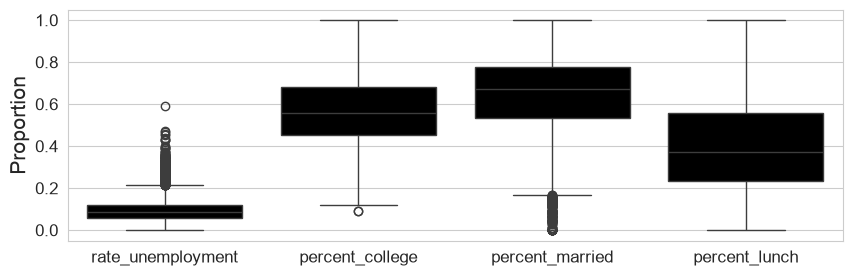

In [17]:
plt.figure(figsize=(10,3))

fractions = list(numerical_predictors)
fractions.remove('median_income')

sns.boxplot(data=df[fractions], color='k')

plt.ylabel('Proportion', fontsize=15)

plt.tick_params(labelsize=12)

plt.show()

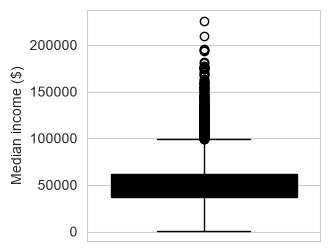

In [18]:
plt.figure(figsize=(3,3))

sns.boxplot(data=df, y='median_income', color='k')

plt.ylabel('Median income ($)')

plt.show()

There are outliers in rate_unemployment, percent_college, percent_married and median_income.

## Explore relationships between the variables and ACT score

### Plot the correlation matrix of the numerical variables to explore relationships between the variables.

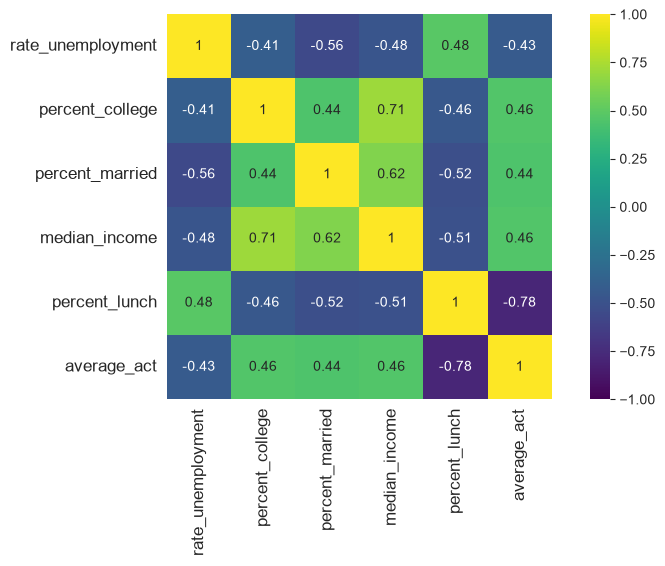

In [19]:
corr_matrix = df[numerical_predictors + ['average_act']].corr()

plt.figure(figsize=(10,5))

sns.heatmap(corr_matrix, vmax=1, vmin=-1, square=True, annot=True, cmap="viridis")

plt.tick_params(labelsize=12)
plt.savefig("/Users/anhtuyet15999/Projects/education/reports/correlation_matrix.png", dpi=300, bbox_inches="tight")

plt.show()

The correlation matrix shows that the percentage of students eligible for free or reduced-price lunch has the strongest relationship with average ACT scores (r=-0.78). College, median household income, and the percentage of children in married-couple families are moderately positively correlated with ACT scores, while unemployment is moderately negatively correlated with ACT scores.

### Make pair plots to explore relationships between the variables

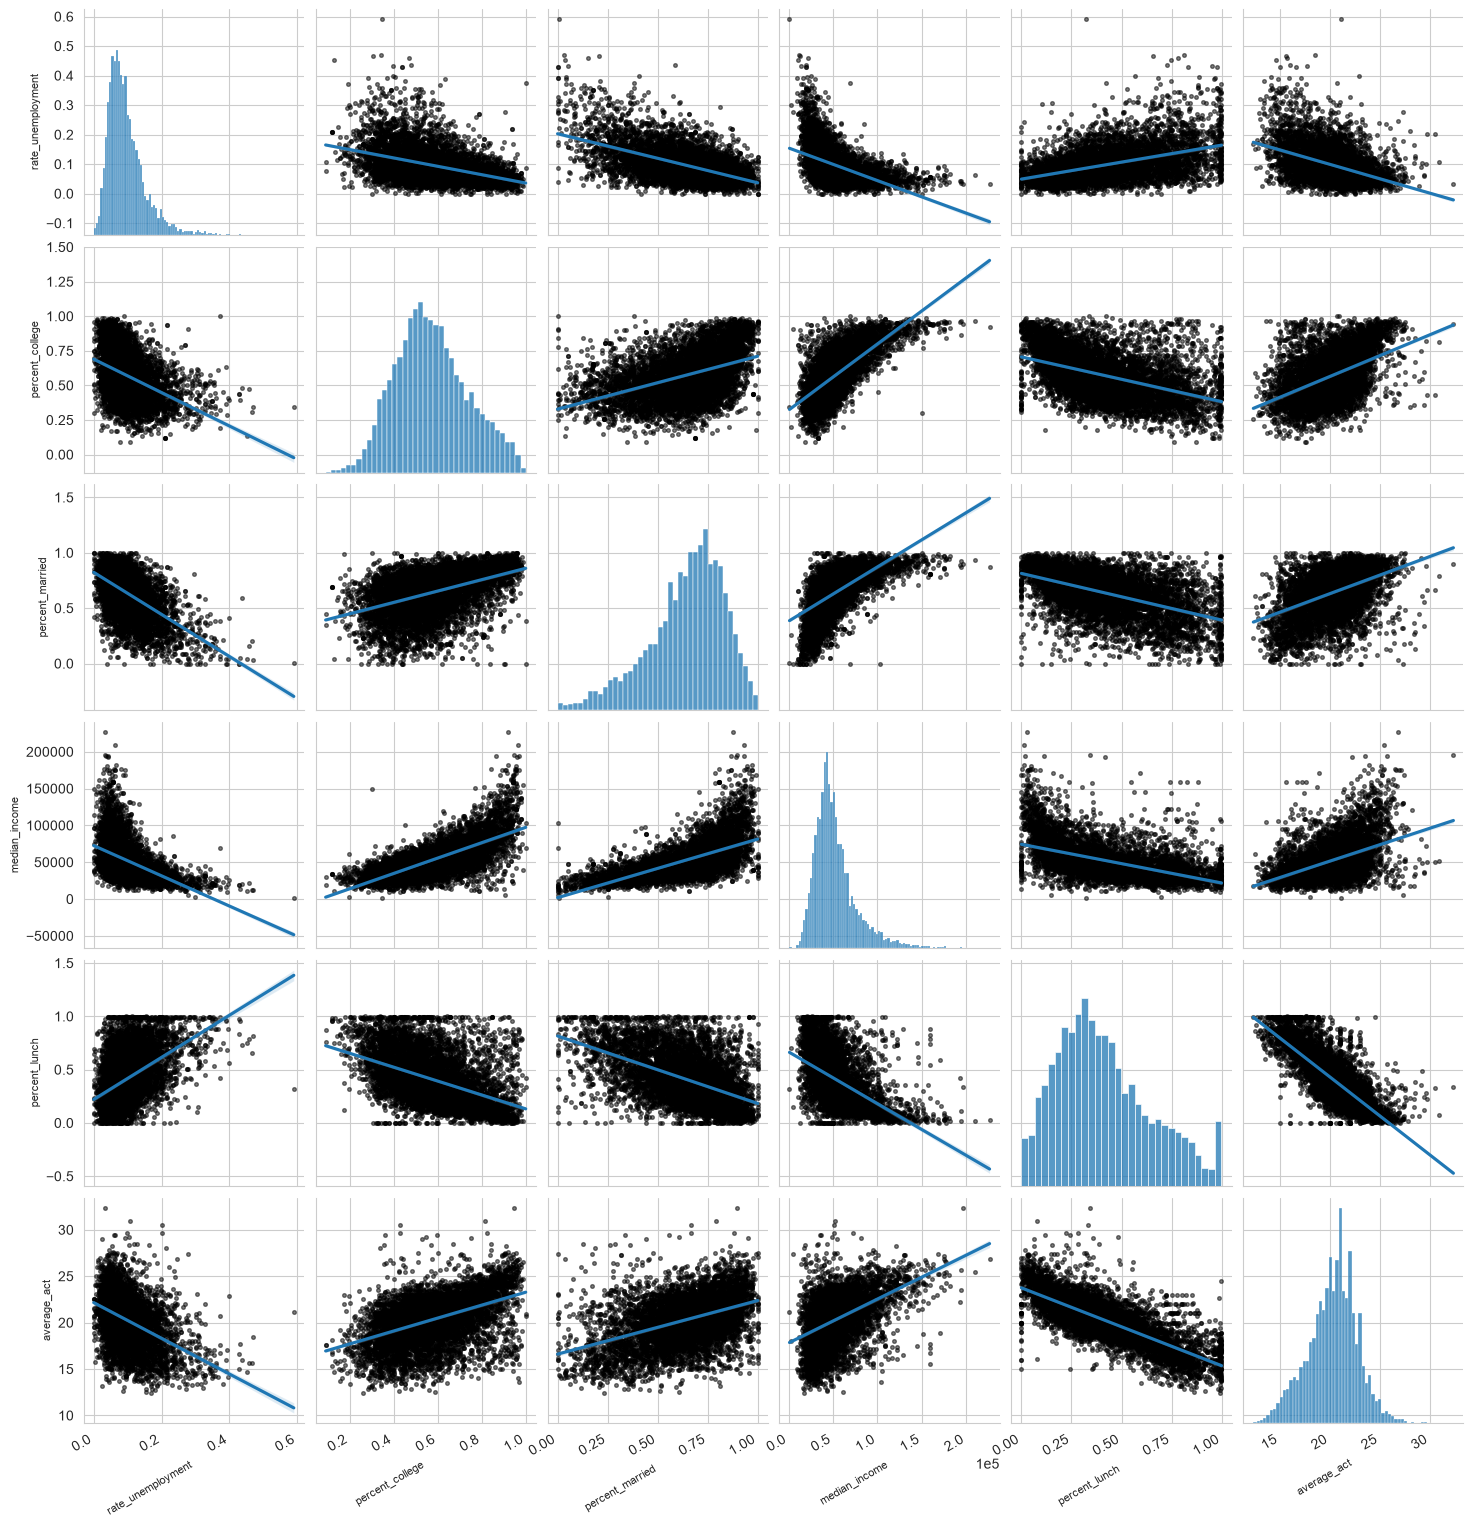

In [20]:
fig = sns.pairplot(data=df, vars=numerical_predictors + ['average_act'], kind="reg", plot_kws={"scatter_kws":{"alpha": 0.5 ,"color":"k","s":7}})

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'median_income':
        ax.ticklabel_format(style='sci', axis='x', scilimits=(0, 0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize=8, rotation=30, ha='right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize=8)

    # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(),rotation=30, ha='right')

plt.show()

The socioeconomic variables show associations with school average ACT scores, although the strength and scatter of these relationships vary. Some predictors have skewed distributions and potential outliers. Transformations may be considered.

## Comparison Across School Locales

How do ACT scores and socioeconomic conditions differ between cities, suburbs, towns, and rural areas?

### ACT Scores by School Locale

In [21]:
locale_order = ["City", "Suburban", "Town", "Rural"]

act_by_locale = df.groupby("locale_group")["average_act"].describe().round(2).reindex(locale_order)
act_by_locale

,count,mean,std,min,25%,50%,75%,max
locale_group,,,,,,,,
City,1628.0,18.91,3.24,12.36,16.37,18.49,21.20,32.36
Suburban,2235.0,21.08,2.49,12.50,19.43,21.28,22.80,28.97
Town,1108.0,20.34,1.69,15.32,19.24,20.35,21.50,25.57
Rural,2256.0,20.50,1.72,14.71,19.30,20.62,21.74,27.28


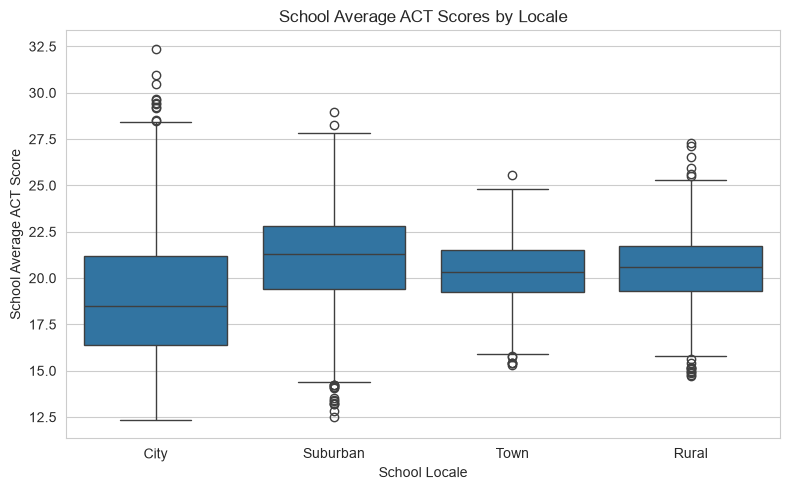

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="locale_group", y="average_act", order=locale_order)

plt.xlabel("School Locale")
plt.ylabel("School Average ACT Score")
plt.title("School Average ACT Scores by Locale")

plt.tight_layout()
plt.savefig("/Users/anhtuyet15999/Projects/education/reports/act_by_locale.png",dpi=300, bbox_inches="tight")
plt.show()

Suburban schools have the highest mean and median ACT scores (21.08 and 21.28), while city schools have the lowest (18.91 and 18.49). The mean difference between these groups is approximately 2.18 points. City schools also show the greatest variability (SD = 3.24; IQR = 4.83), including some schools with very high scores. Town and rural schools have similar average scores and less variability. Despite these differences, the score distributions overlap considerably across locales.

### Socioeconomic Characteristics by School Locale

In [23]:
socioeconomic_by_locale = df.groupby("locale_group")[numerical_predictors].median().round(2).reindex(locale_order)
socioeconomic_by_locale

,rate_unemployment,percent_college,percent_married,median_income,percent_lunch
locale_group,,,,,
City,0.10,0.57,0.54,40605.0,0.63
Suburban,0.08,0.65,0.71,58574.0,0.27
Town,0.09,0.51,0.62,41381.0,0.38
Rural,0.08,0.51,0.71,47272.5,0.34


Socioeconomic characteristics differ across school locales.
Suburban schools have the highest median household income ($58,574), the highest median college proportion (65%), and the lowest median free or reduced-price lunch proportion (27%). 
City schools have the lowest median household income (40,605), the highest median unemployment rate (10%), and the highest median lunch proportion (63%). 
Rural schools have higher median household income and a lower median lunch proportion than town schools. 
These differences provide context for the ACT score gaps and motivate accounting for socioeconomic characteristics in the modeling stage.

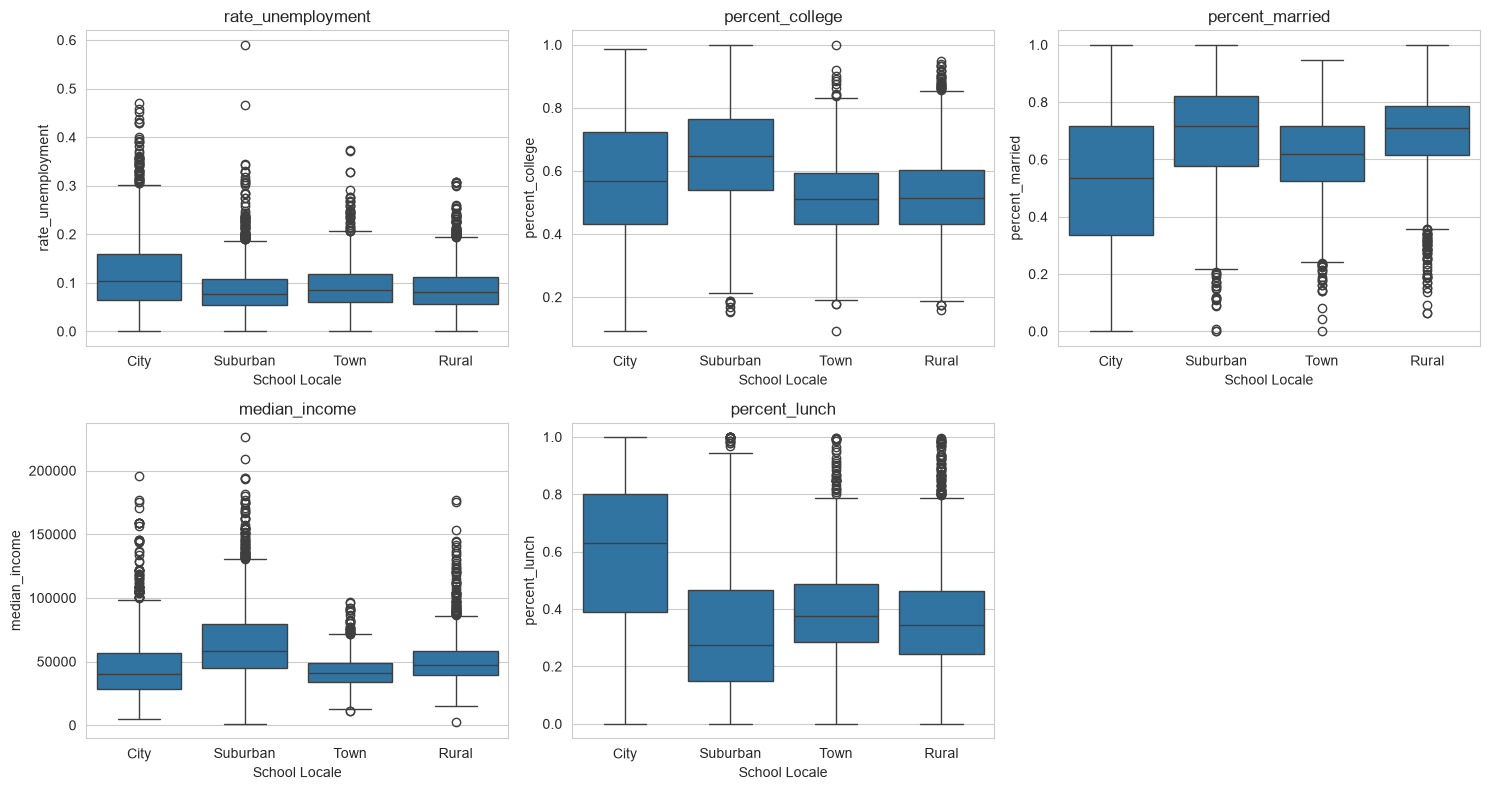

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, variable in zip(axes.flat, numerical_predictors):
    sns.boxplot(data=df, x="locale_group", y=variable, order=locale_order, ax=ax)
    ax.set_title(variable)
    ax.set_xlabel("School Locale")
    ax.set_ylabel(variable)

axes.flat[-1].set_visible(False)

plt.tight_layout()
plt.show()

The boxplots show differences in both the typical levels and variability of socioeconomic variables across locales. City schools have wider interquartile ranges for unemployment, college proportion, married-couple family proportion, and lunch eligibility. Suburban schools generally have higher household income and college proportions, alongside lower lunch eligibility. Nevertheless, the distributions overlap across locales, indicating substantial socioeconomic variation within geographic groups.

# Conclusion
1. Sample coverage: The analytical sample contains 7,227 schools across 20 states. Representation varies across states and locales, which limits generalization to all U.S. high schools.
2. ACT score distribution: School average ACT scores are approximately bell-shaped, with a mean of 20.30 and a median of 20.50. The middle 50% of schools score between 18.80 and 22.00. Potential outliers occur at both ends of the distribution.
3. Socioeconomic relationships: Lunch eligibility has the strongest observed correlation with ACT scores (r = −0.78). College proportion, household income, and married-couple family proportion are positively correlated with ACT scores, while unemployment is negatively correlated.
4. Differences across locales: Suburban schools have the highest mean ACT score (21.08), while city schools have the lowest (18.91) and the greatest variability. Town and rural schools have similar mean scores. Score distributions overlap considerably across all four groups.
5. Socioeconomic differences across locales: Suburban schools generally have higher household income and college proportions and lower lunch eligibility. City schools have higher median unemployment and lunch eligibility. These differences provide context for the observed ACT score gaps.